# 06. Підсумкові результати

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import cohen_kappa_score

sys.path.append(str(Path("..").resolve()))
from fabula_annotation import read_annotation_workbook
from fabula_eval import LEVELS, evaluate

ROOT = Path("..")
RESULTS = ROOT / "results"
OUTPUT_DIR = RESULTS / "06"
FIGURES_DIR = ROOT.resolve().parent / "docs" / "figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
LEVEL_TO_ID = {"A1": 0, "A2": 1, "B1": 2, "B2": 3, "C1": 4, "C2": 4}
ANNOTATOR_TO_ID = {1: 0, 2: 1, 3: 2, 4: 3, 5: 4, 6: 4}
MODELS = ["M0 rules", "M1 Logistic Regression", "M2 Random Forest", "M3 DistilBERT", "M4-13", "M4-33", "M4-final"]
TRANSFORMER_RUNS = {"M3 DistilBERT": "M3", "M4-13": "M4_rf13", "M4-33": "M4_all33", "M4-final": "M4_final"}
COLORS = {"cefr": "#2F3E9E", "raw": "#E5483B", "calibrated": "#3E8E5A"}
tables = {}

## 1. Дані

In [2]:
splits = {name: pd.read_csv(ROOT / "data" / "processed" / f"cefr_sp_{name}.csv") for name in ["train", "validation", "test"]}
gold = pd.read_csv(RESULTS / "05" / "gold.csv")

data_summary = pd.DataFrame({
    **{f"CEFR-SP {name}": frame["level"].value_counts().reindex(LEVELS) for name, frame in splits.items()},
    "Діалоги (DailyDialog)": gold["level_class"].value_counts().reindex(LEVELS),
}).fillna(0).astype(int)
data_summary.loc["усього"] = data_summary.sum()
tables["01_data"] = data_summary
data_summary

,CEFR-SP train,CEFR-SP validation,CEFR-SP test,Діалоги (DailyDialog)
A1,87,19,18,52
A2,890,190,191,79
B1,2313,495,496,83
B2,2331,499,500,64
C,1381,297,296,22
усього,7002,1500,1501,300


## 2. Узгодженість людської розмітки

In [3]:
cefr_all = pd.concat(splits.values())
a, b = cefr_all["label_a"].map(ANNOTATOR_TO_ID), cefr_all["label_b"].map(ANNOTATOR_TO_ID)
round1 = read_annotation_workbook(ROOT / "annotation" / "dialogues_round1.xlsx")
round2 = read_annotation_workbook(ROOT / "annotation" / "dialogues_round2.xlsx")
repeat = round1.merge(round2, on="item_id", suffixes=("_1", "_2"))
first, second = repeat["level_1"].map(LEVEL_TO_ID), repeat["level_2"].map(LEVEL_TO_ID)


def agreement(x, y):
    difference = (x - y).abs()
    return {"пар": len(x), "точний збіг": (difference == 0).mean(), "збіг ±1": (difference <= 1).mean(),
            "QWK": cohen_kappa_score(x, y, weights="quadratic")}


agreement_table = pd.DataFrame({
    "CEFR-SP: фахівець A проти B": agreement(a, b),
    "Діалоги: авторка, повтор одразу": agreement(first, second),
}).T
tables["02_agreement"] = agreement_table
agreement_table.round(3)

,пар,точний збіг,збіг ±1,QWK
CEFR-SP: фахівець A проти B,10003.0,0.434,1.00,0.746
"Діалоги: авторка, повтор одразу",75.0,0.627,0.96,0.825


## 3. Зведена таблиця моделей

In [4]:
classic_test = pd.read_csv(RESULTS / "03_test.csv", index_col=0)
classic_rows = {"M0 rules": "M0 rules", "M1 Logistic Regression": "M1 Logistic Regression [max]",
                "M2 Random Forest": "M2 Random Forest [max], 13 ознак"}
runs = pd.read_csv(RESULTS / "04" / "runs.csv")


def cefr_metric(model, metric):
    if model in classic_rows:
        return f"{float(classic_test.loc[classic_rows[model], metric]):.3f}"
    values = runs.loc[runs["name"] == TRANSFORMER_RUNS[model], f"test_{metric}"]
    return f"{values.mean():.3f} ± {values.std():.3f}"


predictions = pd.read_csv(RESULTS / "05" / "predictions.csv")
y_dialog = gold["level_id"].to_numpy()
raw_dialog = {model: evaluate(y_dialog, predictions[model].map(LEVEL_TO_ID | {"C": 4}).to_numpy()) for model in MODELS}
calibrated = pd.read_csv(RESULTS / "05" / "calibration_cv.csv").groupby("name").mean(numeric_only=True)
spearman = pd.read_csv(RESULTS / "05" / "spearman.csv", index_col=0)

rows = {}
for model in MODELS:
    rows[model] = {
        "CEFR-SP accuracy": cefr_metric(model, "accuracy"),
        "CEFR-SP macro-F1": cefr_metric(model, "macro_f1"),
        "CEFR-SP macro-F1 м'яка": cefr_metric(model, "macro_f1_lenient"),
        "CEFR-SP ±1": cefr_metric(model, "adjacent_accuracy"),
        "CEFR-SP QWK": cefr_metric(model, "qwk"),
        "Діалоги accuracy": round(raw_dialog[model]["accuracy"], 3),
        "Діалоги macro-F1": round(raw_dialog[model]["macro_f1"], 3),
        "Діалоги+кал. accuracy": round(calibrated.loc[model, "accuracy"], 3) if model in calibrated.index else "—",
        "Діалоги+кал. macro-F1": round(calibrated.loc[model, "macro_f1"], 3) if model in calibrated.index else "—",
        "Діалоги+кал. ±1": round(calibrated.loc[model, "adjacent_accuracy"], 3) if model in calibrated.index else "—",
        "Діалоги+кал. QWK": round(calibrated.loc[model, "qwk"], 3) if model in calibrated.index else "—",
        "Діалоги Спірмен": round(spearman.loc[model, "діалоги"], 3) if model in spearman.index else "—",
    }
main_table = pd.DataFrame(rows).T
tables["03_models"] = main_table
main_table

,CEFR-SP accuracy,CEFR-SP macro-F1,CEFR-SP macro-F1 м'яка,CEFR-SP ±1,CEFR-SP QWK,Діалоги accuracy,Діалоги macro-F1,Діалоги+кал. accuracy,Діалоги+кал. macro-F1,Діалоги+кал. ±1,Діалоги+кал. QWK,Діалоги Спірмен
M0 rules,0.440,0.395,0.611,0.912,0.591,0.447,0.427,0.396,0.396,0.828,0.613,0.67
M1 Logistic Regression,0.616,0.532,0.675,0.989,0.764,0.387,0.268,—,—,—,—,—
M2 Random Forest,0.622,0.580,0.729,0.983,0.770,0.43,0.33,0.493,0.491,0.867,0.645,0.683
M3 DistilBERT,0.665 ± 0.003,0.619 ± 0.003,0.746 ± 0.026,0.997 ± 0.001,0.815 ± 0.003,0.38,0.206,0.481,0.483,0.917,0.711,0.738
M4-13,0.676 ± 0.010,0.623 ± 0.005,0.749 ± 0.007,0.996 ± 0.000,0.819 ± 0.003,0.373,0.197,0.501,0.503,0.917,0.709,0.746
M4-33,0.672 ± 0.005,0.619 ± 0.009,0.751 ± 0.004,0.996 ± 0.000,0.817 ± 0.003,0.39,0.223,0.502,0.504,0.91,0.706,0.746
M4-final,0.676 ± 0.005,0.626 ± 0.006,0.745 ± 0.009,0.996 ± 0.000,0.820 ± 0.004,0.397,0.217,0.501,0.501,0.923,0.728,0.754


## 4. Головний графік: CEFR-SP, діалоги, діалоги після калібрування

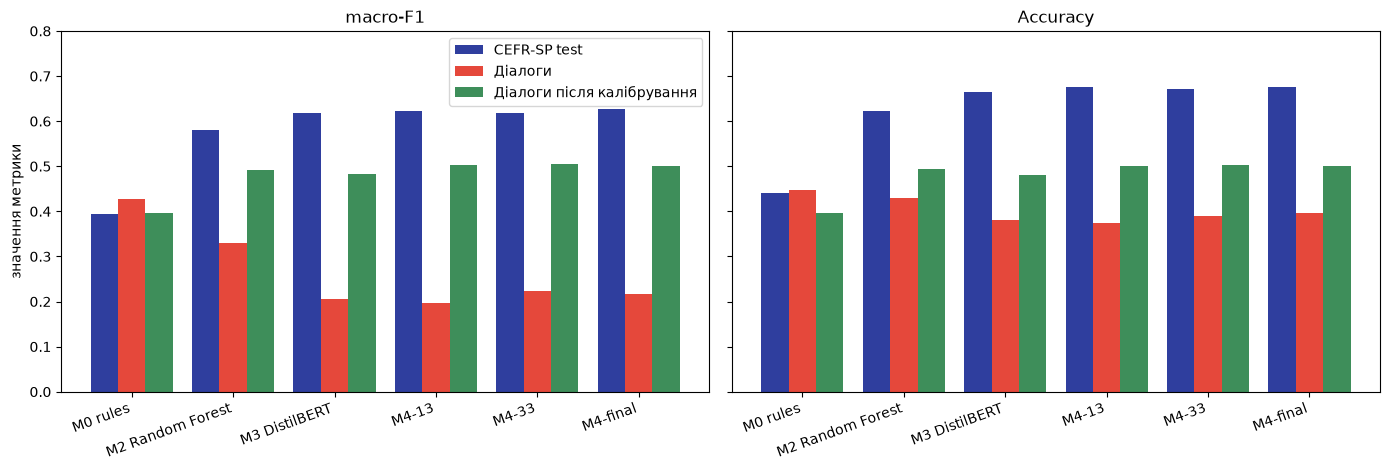

In [5]:
plot_models = [model for model in MODELS if model in calibrated.index]
cefr_f1 = [float(cefr_metric(model, "macro_f1").split(" ")[0]) for model in plot_models]
cefr_accuracy = [float(cefr_metric(model, "accuracy").split(" ")[0]) for model in plot_models]
positions = np.arange(len(plot_models))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for ax, metric, cefr_values, title in [
    (axes[0], "macro_f1", cefr_f1, "macro-F1"),
    (axes[1], "accuracy", cefr_accuracy, "Accuracy"),
]:
    raw = [raw_dialog[model][metric] for model in plot_models]
    calibrated_values = [calibrated.loc[model, metric] for model in plot_models]
    ax.bar(positions - 0.27, cefr_values, width=0.27, color=COLORS["cefr"], label="CEFR-SP test")
    ax.bar(positions, raw, width=0.27, color=COLORS["raw"], label="Діалоги")
    ax.bar(positions + 0.27, calibrated_values, width=0.27, color=COLORS["calibrated"], label="Діалоги після калібрування")
    ax.set_xticks(positions, plot_models, rotation=20, ha="right")
    ax.set_title(title)
    ax.set_ylim(0, 0.8)
axes[0].set_ylabel("значення метрики")
axes[0].legend(loc="upper right")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "06_main_result.png", dpi=200)
plt.show()

## 5. Скільки розмічених діалогів потрібно

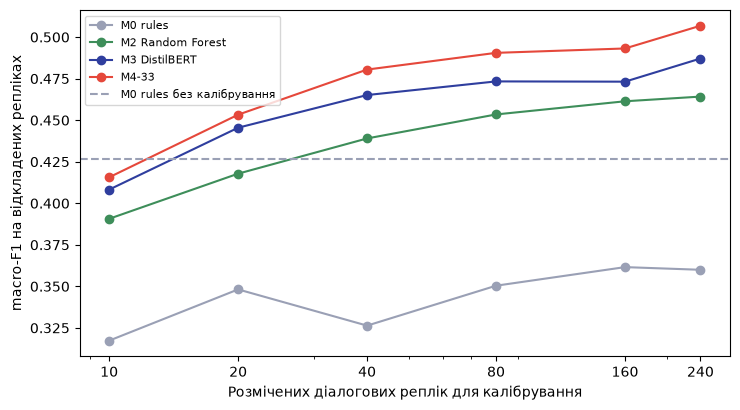

,M0 rules,M2 Random Forest,M3 DistilBERT,M4-33
size,,,,
10,0.317,0.391,0.408,0.416
20,0.348,0.418,0.445,0.453
40,0.326,0.439,0.465,0.480
80,0.350,0.453,0.473,0.491
160,0.362,0.461,0.473,0.493
240,0.360,0.464,0.487,0.507


In [6]:
curve = pd.read_csv(RESULTS / "05" / "calibration_curve.csv", index_col=0)
raw_m0 = raw_dialog["M0 rules"]["macro_f1"]
fig, ax = plt.subplots(figsize=(7.5, 4.2))
styles = {"M0 rules": "#9AA0B5", "M2 Random Forest": "#3E8E5A", "M3 DistilBERT": "#2F3E9E", "M4-33": "#E5483B"}
for model in curve.columns:
    ax.plot(curve.index, curve[model], marker="o", color=styles.get(model, "#1E2766"), label=model)
ax.axhline(raw_m0, color="#9AA0B5", linestyle="--", label="M0 rules без калібрування")
ax.set_xscale("log")
ax.set_xticks(curve.index, curve.index)
ax.set_xlabel("Розмічених діалогових реплік для калібрування")
ax.set_ylabel("macro-F1 на відкладених репліках")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "06_calibration_curve.png", dpi=200)
plt.show()
tables["05_calibration_curve"] = curve.round(3)
curve.round(3)

## 6. Відбір ознак

In [7]:
ablation = pd.read_csv(RESULTS / "03_ablation.csv", index_col=0)
group_importance = (pd.read_csv(RESULTS / "04" / "permutation_importance.csv")
                    .query("kind == 'group'").groupby("name")["importance"].mean())
feature_summary = pd.DataFrame({
    "Random Forest: macro-F1 без групи": {group: ablation.loc[f"без {group}", "macro_f1"] for group in group_importance.index},
    "Random Forest: зміна": {group: ablation.loc[f"без {group}", "зміна"] for group in group_importance.index},
    "Гібрид M4-33: важливість групи": group_importance,
})
tables["06_feature_groups"] = feature_summary.round(4)
selected_rf = json.load(open(RESULTS / "03_selected_features.json", encoding="utf-8"))["features"]
selected_m4 = json.load(open(RESULTS / "04" / "selected_features_m4.json", encoding="utf-8"))["features"]
print(f"Відібрано для Random Forest: {len(selected_rf)}; для гібрида: {len(selected_m4)}; спільних: {len(set(selected_rf) & set(selected_m4))}")
feature_summary.round(4)

Відібрано для Random Forest: 13; для гібрида: 23; спільних: 11


,Random Forest: macro-F1 без групи,Random Forest: зміна,Гібрид M4-33: важливість групи
dialogue,0.6331,0.0118,0.0031
grammar,0.6003,-0.0210,0.0034
length,0.5542,-0.0671,0.0047
lexical,0.4914,-0.1299,0.0040


## 7. Фінальна модель

In [8]:
final = json.load(open(RESULTS / "05" / "final_model.json", encoding="utf-8"))
final_row = main_table.loc[final["model"]]
final_summary = pd.Series({
    "модель": final["model"],
    "файл": final["file"],
    "ознак": len(selected_m4),
    "пороги (очікуваний рівень)": ", ".join(f"{value:.2f}" for value in final["thresholds"]),
    "CEFR-SP accuracy": final_row["CEFR-SP accuracy"],
    "CEFR-SP macro-F1": final_row["CEFR-SP macro-F1"],
    "Діалоги+кал. accuracy": final_row["Діалоги+кал. accuracy"],
    "Діалоги+кал. macro-F1": final_row["Діалоги+кал. macro-F1"],
    "Діалоги+кал. ±1": final_row["Діалоги+кал. ±1"],
}).to_frame("значення")
tables["07_final_model"] = final_summary
final_summary

,значення
модель,M4-final
файл,m4_hybrid.pt
ознак,23
пороги (очікуваний рівень),"0.91, 1.25, 1.90, 2.26"
CEFR-SP accuracy,0.676 ± 0.005
CEFR-SP macro-F1,0.626 ± 0.006
Діалоги+кал. accuracy,0.501
Діалоги+кал. macro-F1,0.501
Діалоги+кал. ±1,0.923


## 8. Експорт таблиць

In [9]:
with pd.ExcelWriter(OUTPUT_DIR / "06_tables.xlsx") as writer:
    for name, table in tables.items():
        table.to_excel(writer, sheet_name=name[:31])
        table.to_csv(OUTPUT_DIR / f"{name}.csv", encoding="utf-8-sig")
sorted(path.name for path in OUTPUT_DIR.iterdir())

['01_data.csv',
 '02_agreement.csv',
 '03_models.csv',
 '05_calibration_curve.csv',
 '06_feature_groups.csv',
 '06_tables.xlsx',
 '07_final_model.csv']

## 9. Висновки

- Дані: CEFR-SP 10 003 речення (train 7002, validation 1500, test 1501), A1 лише 1.2%; діалоги — 300 реплік DailyDialog, розмічених авторкою (A1 52, A2 79, B1 83, B2 64, C 22).
- Узгодженість людей: фахівці CEFR-SP між собою — точний збіг 0.434, ±1 1.00, QWK 0.746; авторка з собою (повтор одразу) — 0.627, 0.96, 0.825.
- CEFR-SP test: найкраща модель — гібрид M4 (accuracy 0.676, macro-F1 0.626, ±1 0.996, QWK 0.820); DistilBERT 0.665 / 0.619; Random Forest 0.622 / 0.580; правила M0 0.440 / 0.395.
- Діалоги без калібрування: навчені моделі падають (macro-F1 трансформерів 0.20–0.22, Random Forest 0.33), M0 — ні (0.43).
- Діалоги після калібрування порогів: трансформери 0.48–0.50 accuracy і macro-F1, ±1 0.91–0.92, QWK 0.71–0.73; Random Forest 0.49 / 0.49; M0 0.40.
- За кореляцією Спірмена трансформери впорядковують діалоги найкраще (0.74–0.75), M0 — найгірше (0.67): падіння — це зсув шкали, а не втрата розуміння складності.
- 20 розмічених реплік достатньо, щоб відкалібрований трансформер обігнав M0.
- Відбір ознак: для Random Forest найважливіші лексичні (−0.130 без групи) і довжинні (−0.067); для гібрида всі групи важать ≤ 0.005. Відібрано 13 ознак для Random Forest і 23 для гібрида, 11 спільних.
- Фінальна модель: M4-final з порогами, відкаліброваними на 300 репліках: CEFR-SP accuracy 0.676, діалоги accuracy 0.501, ±1 0.923.